In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('/content/Titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [5]:
df.shape
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [6]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [7]:
# Fill Age with mean
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Fill Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop Cabin (too many missing values)
if 'Cabin' in df.columns:
    df = df.drop('Cabin', axis=1)

In [8]:
# Convert Sex to numeric
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Convert Embarked using one-hot encoding
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

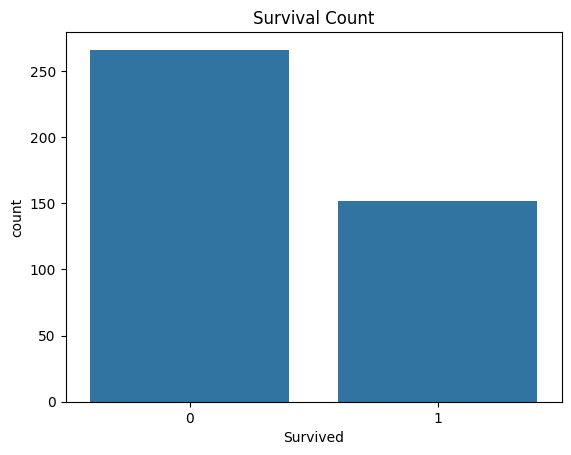

In [9]:
sns.countplot(x='Survived', data=df)
plt.title("Survival Count")
plt.show()

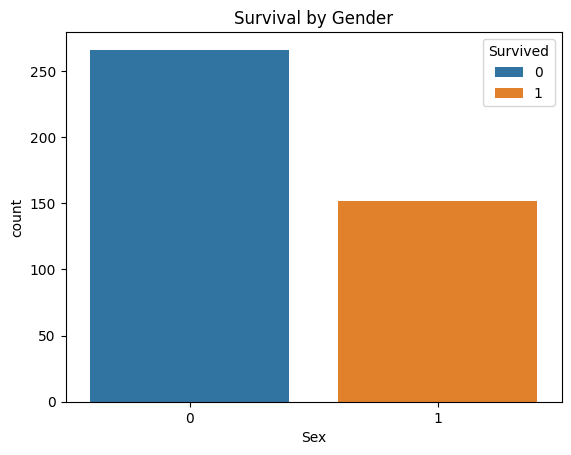

In [10]:
sns.countplot(x='Sex', hue='Survived', data=df)
plt.title("Survival by Gender")
plt.show()

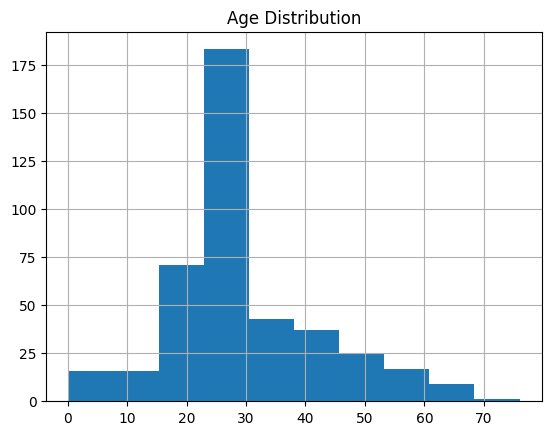

In [11]:
df['Age'].hist()
plt.title("Age Distribution")
plt.show()

In [12]:
# Drop unnecessary columns if present
drop_cols = ['Name', 'Ticket', 'PassengerId']
df = df.drop(columns=[col for col in drop_cols if col in df.columns])

# Define X and y
X = df.drop('Survived', axis=1)
y = df['Survived']

In [13]:
X = X.fillna(X.mean())

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [16]:
y_pred = model.predict(X_test)

In [17]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


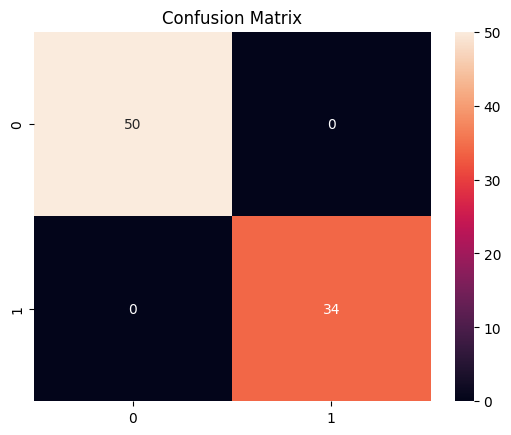

In [18]:
from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True)
plt.title("Confusion Matrix")
plt.show()

In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        34

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84



In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 1.0


In [21]:
# Install Gradio
!pip install gradio

import gradio as gr
import numpy as np

# Make sure your trained model is named: model

def predict_survival(Pclass, Sex, Age, SibSp, Parch, Fare, Embarked):

    # Convert inputs to match training format
    sex = 0 if Sex == "Male" else 1

    # One-hot encoding for Embarked
    Embarked_Q = 1 if Embarked == "Q" else 0
    Embarked_S = 1 if Embarked == "S" else 0

    # Input array (adjust order SAME as training X columns)
    input_data = np.array([[Pclass, sex, Age, SibSp, Parch, Fare, Embarked_Q, Embarked_S]])

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        return "✅ Survived"
    else:
        return "❌ Did Not Survive"

# UI
ui = gr.Interface(
    fn=predict_survival,
    inputs=[
        gr.Dropdown([1,2,3], label="Passenger Class"),
        gr.Radio(["Male","Female"], label="Gender"),
        gr.Number(label="Age"),
        gr.Number(label="Siblings/Spouses"),
        gr.Number(label="Parents/Children"),
        gr.Number(label="Fare"),
        gr.Radio(["C","Q","S"], label="Embarked")
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="🚢 Titanic Survival Prediction",
    description="Enter passenger details to predict survival"
)

# Launch in Colab
ui.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6f0608647667884634.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
